# AI Roots — Anatomia de um agente

**O loop, não a mágica.**

Um agente ReAct completo, sem framework nenhum, rodando contra a API de verdade — e a
instrumentação que mostra o que esse loop custa.

A tese da live em uma frase: um agente é um `while` com um LLM escolhendo a próxima
ferramenta, e o custo desse loop cresce com o **quadrado** dos passos, não com o número deles.

> Modelo: **Haiku**. É barato o bastante para rodar o loop dezenas de vezes na live sem
> pensar na conta — e o ponto desta aula é o *mecanismo*, não a capacidade do modelo.

## 1. Setup

No Colab, rode esta célula uma vez. O `-q` só deixa a saída limpa.

In [1]:
!pip -q install "anthropic>=0.40"

import json, re, textwrap
import matplotlib.pyplot as plt
import numpy as np
import anthropic

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
print("anthropic", anthropic.__version__)

anthropic 2.7.0


## 2. A chave de API

No Colab, o caminho certo é o **painel de Secrets** (ícone de chave na barra lateral):
crie um secret chamado `ANTHROPIC_API_KEY` e ligue o acesso para este notebook.

Assim a chave não fica no código e não vai junto quando você compartilhar o notebook —
o que importa se você for gravar a tela.

In [2]:
import os

from google.colab import userdata
os.environ["ANTHROPIC_API_KEY"] = userdata.get("ANTHROPIC_API_KEY")

client = anthropic.Anthropic()
MODELO = "claude-haiku-5-5"     # troque aqui se quiser comparar com um modelo maior
print("cliente pronto —", MODELO)

cliente pronto — claude-haiku-5-5


## 3. A base de testes

Oito anos, quatro unidades de negócio e um bloco de notas explicativas por ano.

Duas decisões de propósito, e as duas importam para a live:

1. **A base tem armadilhas plantadas.** A queda de 2020, a aquisição que infla o Nordeste
   em 2023 e a mudança de critério contábil em 2024 fazem a comparação ingênua entre dois
   anos ser *enganosa*. O agente só acerta se for ler as notas.
2. **As notas são longas, como no mundo real.** Uma ferramenta de produção não devolve uma
   linha: devolve trecho de documento, JSON de API, linha de log. Esse tamanho é o `d` da
   fórmula — e é ele que manda no custo do loop.

In [3]:
UNIDADES = ["Sudeste", "Sul", "Nordeste", "Centro-Oeste"]

# Faturamento anual por unidade, em reais.
FATURAMENTO = {
    2018: {"Sudeste": 2_310_000.0, "Sul": 1_040_000.0, "Nordeste":   620_000.0, "Centro-Oeste": 310_000.0},
    2019: {"Sudeste": 2_585_000.0, "Sul": 1_172_000.0, "Nordeste":   698_000.0, "Centro-Oeste": 356_000.0},
    2020: {"Sudeste": 2_104_000.0, "Sul":   948_000.0, "Nordeste":   601_000.0, "Centro-Oeste": 289_000.0},
    2021: {"Sudeste": 2_790_000.0, "Sul": 1_263_000.0, "Nordeste":   742_000.0, "Centro-Oeste": 395_000.0},
    2022: {"Sudeste": 3_145_000.0, "Sul": 1_418_000.0, "Nordeste":   830_000.0, "Centro-Oeste": 447_000.0},
    2023: {"Sudeste": 3_402_000.0, "Sul": 1_531_000.0, "Nordeste": 1_654_000.0, "Centro-Oeste": 493_000.0},
    2024: {"Sudeste": 3_688_000.0, "Sul": 1_659_000.0, "Nordeste": 1_812_000.0, "Centro-Oeste": 541_000.0},
    2025: {"Sudeste": 4_015_000.0, "Sul": 1_804_000.0, "Nordeste": 1_974_000.0, "Centro-Oeste": 598_000.0},
}

# Evento específico de cada exercício — é o que muda a leitura do número.
EVENTOS = {
    2018: "Exercício sem eventos extraordinários. Base de comparação considerada limpa pela auditoria.",
    2019: "Abertura de dois centros de distribuição no Sul no segundo semestre, com efeito parcial na receita do exercício.",
    2020: "Retração generalizada por suspensão de operações presenciais entre março e agosto. Houve diferimento de R$ 212 mil de receita reconhecida apenas em 2021.",
    2021: "Reconhecimento do diferimento de 2020. Parte do crescimento aparente sobre 2020 é efeito de base, não de expansão real.",
    2022: "Reajuste contratual indexado ao IPCA aplicado à carteira recorrente. Crescimento majoritariamente de preço, não de volume.",
    2023: "AQUISIÇÃO da Vetor Nordeste S.A., consolidada integralmente a partir de 1º de abril. A unidade Nordeste NAO e comparavel com exercicios anteriores sem ajuste pro forma.",
    2024: "MUDANCA DE CRITERIO: fretes sobre vendas passaram a ser apresentados como receita bruta, e nao como reducao de custo. Efeito estimado de R$ 164 mil sobre a receita, sem impacto no resultado.",
    2025: "Exercício sem mudança de critério. Primeira base plenamente comparável com 2024.",
}

# Boilerplate contábil — realista e repetitivo, como em relatório de verdade.
_BOILERPLATE = (
    "Receita bruta consolidada apurada conforme IFRS 15, líquida de devoluções, abatimentos e "
    "descontos comerciais concedidos no ato da venda. As obrigações de desempenho são satisfeitas "
    "no momento da transferência de controle ao cliente, exceto nos contratos de serviço continuado, "
    "em que o reconhecimento é proporcional ao período decorrido. Tributos sobre vendas encontram-se "
    "destacados na nota 7 e não compõem esta linha. Variações cambiais de contratos denominados em "
    "dólar norte-americano são registradas em resultado financeiro, fora da receita. A base de rateio "
    "de centros de custo entre as unidades segue o critério descrito na nota 3, revisado anualmente "
    "pela administração. Operações entre partes relacionadas foram eliminadas na consolidação. "
    "Os valores aqui apresentados não consideram ajustes pro forma de aquisições ocorridas no exercício, "
    "cuja reconciliação consta do anexo VII do relatório da administração. "
)


def _notas(ano: int) -> str:
    return (f"NOTAS EXPLICATIVAS — EXERCÍCIO {ano}\n"
            f"Evento do exercício: {EVENTOS[ano]}\n"
            f"Critérios gerais: {_BOILERPLATE * 2}"
            f"Parecer: auditoria independente sem ressalvas para o exercício {ano}.")


NOTAS = {ano: _notas(ano) for ano in FATURAMENTO}

print(f"{len(FATURAMENTO)} exercícios · {len(UNIDADES)} unidades")
print(f"Nota de um ano: ~{len(NOTAS[2023])} caracteres (~{len(NOTAS[2023])//4} tokens)")
print(f"Consolidado 2024: R$ {sum(FATURAMENTO[2024].values()):,.2f}")

8 exercícios · 4 unidades
Nota de um ano: ~2152 caracteres (~538 tokens)
Consolidado 2024: R$ 7,700,000.00


## 4. As ferramentas

**O schema é prompt.** O modelo só sabe o que a `description` conta — ferramenta chamada na
hora errada quase nunca é culpa do modelo, é descrição ruim. Dá para resolver bug de agente
editando só essa string.

**Erro vira observação, nunca exception.** Repare que `buscar_faturamento` com ano inválido
devolve a lista de anos disponíveis: você não só informa o erro, você entrega o caminho de
volta. É isso que dá ao modelo a chance de se corrigir sozinho dentro do mesmo loop.

In [4]:
def listar_anos() -> str:
    """Barato de propósito: devolve só o índice, não os dados."""
    return f"Exercícios disponíveis: {sorted(FATURAMENTO)}. Unidades: {UNIDADES}."


def buscar_faturamento(ano: int, unidade: str | None = None) -> str:
    ano = int(ano)
    if ano not in FATURAMENTO:
        return f"ERRO: exercício {ano} não existe. Disponíveis: {sorted(FATURAMENTO)}"
    if unidade:
        if unidade not in UNIDADES:
            return f"ERRO: unidade '{unidade}' não existe. Disponíveis: {UNIDADES}"
        return f"Faturamento {ano} / {unidade}: R$ {FATURAMENTO[ano][unidade]:,.2f}"
    linhas = [f"  {u}: R$ {v:,.2f}" for u, v in FATURAMENTO[ano].items()]
    total = sum(FATURAMENTO[ano].values())
    return (f"Faturamento {ano} por unidade:\n" + "\n".join(linhas) +
            f"\n  CONSOLIDADO: R$ {total:,.2f}")


def buscar_notas(ano: int) -> str:
    """A ferramenta cara: devolve documento, não número. É ela que infla o `d`."""
    ano = int(ano)
    if ano not in NOTAS:
        return f"ERRO: exercício {ano} não existe. Disponíveis: {sorted(NOTAS)}"
    return NOTAS[ano]


def calcular(expressao: str) -> str:
    """O LLM erra aritmética. Terceirize sempre."""
    if not re.fullmatch(r"[0-9\.\+\-\*\/\(\)\s]+", expressao):
        return "ERRO: use apenas números e os operadores + - * / ( )"
    try:
        return f"{eval(expressao, {'__builtins__': {}}, {}):.6g}"   # sandbox pelo regex acima
    except Exception as exc:
        return f"ERRO ao calcular: {exc}"


TOOLS = {"listar_anos": listar_anos, "buscar_faturamento": buscar_faturamento,
         "buscar_notas": buscar_notas, "calcular": calcular}

SCHEMA = [
    {"name": "listar_anos",
     "description": "Lista os exercícios e as unidades de negócio disponíveis na base. Use primeiro, se não souber o que existe.",
     "input_schema": {"type": "object", "properties": {}}},
    {"name": "buscar_faturamento",
     "description": "Faturamento de um exercício. Sem 'unidade', devolve todas as unidades e o consolidado.",
     "input_schema": {"type": "object",
                      "properties": {"ano": {"type": "integer", "description": "Ano com 4 dígitos"},
                                     "unidade": {"type": "string", "enum": UNIDADES}},
                      "required": ["ano"]}},
    {"name": "buscar_notas",
     "description": "Notas explicativas de um exercício: eventos extraordinários, aquisições e mudanças de critério contábil. Consulte SEMPRE antes de comparar dois exercícios.",
     "input_schema": {"type": "object",
                      "properties": {"ano": {"type": "integer", "description": "Ano com 4 dígitos"}},
                      "required": ["ano"]}},
    {"name": "calcular",
     "description": "Avalia uma expressão aritmética. Use SEMPRE para qualquer conta — nunca calcule de cabeça.",
     "input_schema": {"type": "object",
                      "properties": {"expressao": {"type": "string", "description": "Ex: (7115000-5380000)/5380000*100"}},
                      "required": ["expressao"]}},
]

SYSTEM = ("Você é um analista financeiro. Responda usando as ferramentas disponíveis. "
          "Nunca calcule de cabeça: use a ferramenta 'calcular'. "
          "Antes de comparar exercícios, verifique as notas explicativas de ambos. "
          "Quando tiver a resposta final, responda em texto puro, sem chamar mais ferramentas.")

print(f"{len(SCHEMA)} ferramentas registradas")
print(listar_anos())

4 ferramentas registradas
Exercícios disponíveis: [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]. Unidades: ['Sudeste', 'Sul', 'Nordeste', 'Centro-Oeste'].


## 5. O loop

É isto. Um agente é isto.

Três linhas merecem atenção enquanto você lê:

- `messages.append(...)` — **nada é apagado**. O histórico inteiro volta para o modelo a cada
  iteração. É daí que vem o custo quadrático.
- `r.usage.input_tokens` — a conta **medida**, não estimada. Repare que ela sobe a cada passo.
- `max_iter` e `teto` — o critério de parada. Agente sem teto é a coisa mais cara que dá para
  deixar ligada numa sexta à noite.

In [5]:
def rodar_agente(tarefa, max_iter=12, teto=400_000, janela_compaction=None, verboso=True):
    """
    ReAct: pensar -> agir -> observar -> repetir, até resposta final ou teto.

    janela_compaction: se definido, só as N últimas observações ficam inteiras;
    as antigas viram resumo. Reduz o `d` — trocando custo por risco de perder
    exatamente o fato de que o agente precisava.

    Retorna (resposta, trace) com o usage REAL por iteração.
    """
    messages = [{"role": "user", "content": tarefa}]
    trace, gasto, pos_obs = [], 0, []

    for i in range(1, max_iter + 1):
        if janela_compaction is not None:
            for pos in pos_obs[:-janela_compaction]:
                for bloco in messages[pos]["content"]:
                    if len(bloco["content"]) > 200:
                        bloco["content"] = bloco["content"][:190] + " …[resumido]"

        r = client.messages.create(model=MODELO, max_tokens=1024, system=SYSTEM,
                                   tools=SCHEMA, messages=messages)

        entrada = r.usage.input_tokens
        gasto += entrada
        trace.append({"i": i, "input_tokens": entrada, "output_tokens": r.usage.output_tokens})

        if gasto > teto:                       # falha explícita > fatura surpresa
            return "PAROU: orçamento de tokens estourado.", trace

        messages.append({"role": "assistant", "content": r.content})
        usos = [b for b in r.content if b.type == "tool_use"]

        if not usos:                           # resposta final
            texto = "".join(b.text for b in r.content if b.type == "text").strip()
            if verboso:
                print(f"[{i:>2}] RESPOSTA FINAL{'':<34}entrada: {entrada:>6} tok")
            return texto, trace

        saidas = []
        for u in usos:                         # pode pedir várias de uma vez: trate todas
            obs = TOOLS[u.name](**u.input)     # erro volta como texto, não como exception
            saidas.append({"type": "tool_result", "tool_use_id": u.id, "content": obs})
            if verboso:
                arg = str(u.input)[:40]
                print(f"[{i:>2}] {u.name}({arg}){'':<{max(0, 44-len(u.name)-len(arg))}}entrada: {entrada:>6} tok")

        messages.append({"role": "user", "content": saidas})
        pos_obs.append(len(messages) - 1)

    return "PAROU: limite de iterações atingido sem resposta final.", trace

## 6. Rodar

A tarefa abaixo é propositalmente armadilhada: a comparação 2023 → 2024 **parece** um
crescimento limpo, mas a aquisição de 2023 e a mudança de critério de 2024 estão nas notas.

Antes de rodar, pare e pense: **quantas chamadas de ferramenta você acha que ele vai fazer?**
Anote o número. A gente confere daqui a pouco — e a diferença entre o seu palpite e o
resultado é exatamente o que torna o custo de agente difícil de orçar.

In [6]:
TAREFA = (
    "Compare o faturamento consolidado de 2023 com o de 2024: quanto cresceu em percentual "
    "e quanto isso dá por mês em reais? E me diga se essa comparação é confiável como está "
    "ou se tem algo nas notas explicativas que a torna enganosa."
)

resposta, trace = rodar_agente(TAREFA)
print("\n" + "=" * 78)
print(textwrap.fill(resposta, 78))

[ 1] buscar_faturamento({'ano': 2023})             entrada:   1030 tok
[ 1] buscar_faturamento({'ano': 2024})             entrada:   1030 tok
[ 1] buscar_notas({'ano': 2023})                   entrada:   1030 tok
[ 1] buscar_notas({'ano': 2024})                   entrada:   1030 tok
[ 2] calcular({'expressao': '(7700000-7080000)/7080000)entrada:   3278 tok
[ 2] calcular({'expressao': '(7700000-7080000)/12'})entrada:   3278 tok
[ 2] calcular({'expressao': '(7700000-164000-7080000)/)entrada:   3278 tok
[ 2] calcular({'expressao': '(7700000-164000-7080000)/)entrada:   3278 tok
[ 3] RESPOSTA FINAL                                  entrada:   3892 tok

**Resposta curta:** o consolidado cresceu cerca de 8,76% (R$ 620 mil no ano,
ou aproximadamente R$ 51,7 mil por mês). Mas a comparação não é confiável como
está. Ajustando apenas o efeito de mudança de critério, o crescimento cai para
cerca de 6,44% (R$ 456 mil no ano, ou R$ 38 mil por mês). Além disso, há um
efeito de aquisição que não consig

## 7. A matemática do loop

O LLM é **stateless**: ele não lembra do passo anterior, você re-envia tudo. É a conta do
restaurante onde o garçom relê o pedido inteiro a cada rodada — o trabalho dele não é o
número de pedidos, é a *soma de todas as releituras*.

Com prompt base `b` e incremento médio `d` por passo, a entrada acumulada após `n` iterações é

$$T(n) \;=\; \sum_{k=1}^{n}\bigl[b + (k-1)d\bigr] \;=\; \underbrace{n\,b}_{\text{linear}} \;+\; \underbrace{d\,\frac{n(n-1)}{2}}_{\text{quadrático}}$$

- **`n`** — passos do agente; é o que o teto controla
- **`b`** — contexto base (system + schemas + pergunta); pago em **toda** iteração, não só na primeira
- **`d`** — incremento médio por passo; é o tamanho da observação, a variável que todo mundo esquece

O termo que morde é o segundo: soma de progressão aritmética, o mesmo `n²/2` do aperto de mão
de todo mundo com todo mundo.

In [7]:
def custo_teorico(n, b, d):
    """T(n) = n·b + d·n(n-1)/2"""
    return n * b + d * n * (n - 1) / 2.0


entradas = np.array([p["input_tokens"] for p in trace], dtype=float)
n_iter = len(entradas)
b_med = float(entradas[0])
d_med = float((entradas[-1] - entradas[0]) / max(1, n_iter - 1))
total, linear = float(entradas.sum()), b_med * n_iter

print(f"Iterações:                       {n_iter}")
print(f"Contexto na 1ª chamada (b):      {b_med:>8,.0f} tokens")
print(f"Incremento médio por passo (d):  {d_med:>8,.0f} tokens")
print(f"Total de entrada (medido):       {total:>8,.0f} tokens")
print(f"Se fosse linear (n × b):         {linear:>8,.0f} tokens")
print(f"--> o loop custou {total / linear:.2f}x a intuição ingênua")

print("\nCom b = 800 e d = 450 tokens, para conferir no papel:")
for n in (8, 16, 30):
    real, lin = custo_teorico(n, 800, 450), 800 * n
    print(f"  n={n:>2} | real {real:>9,.0f} | linear {lin:>7,.0f} | {real/lin:.1f}x a intuição")
r8, r16 = custo_teorico(8, 800, 450), custo_teorico(16, 800, 450)
print(f"\nDobrar de 8 para 16 passos NÃO dobra o custo: multiplica por {r16/r8:.2f}.")

Iterações:                       3
Contexto na 1ª chamada (b):         1,030 tokens
Incremento médio por passo (d):     1,431 tokens
Total de entrada (medido):          8,200 tokens
Se fosse linear (n × b):            3,090 tokens
--> o loop custou 2.65x a intuição ingênua

Com b = 800 e d = 450 tokens, para conferir no papel:
  n= 8 | real    19,000 | linear   6,400 | 3.0x a intuição
  n=16 | real    66,800 | linear  12,800 | 5.2x a intuição
  n=30 | real   219,750 | linear  24,000 | 9.2x a intuição

Dobrar de 8 para 16 passos NÃO dobra o custo: multiplica por 3.52.


## 8. O gráfico

**Esquerda:** o que a *sua* execução custou — barras são a entrada de cada iteração, a linha
vermelha é o acumulado real, a cinza tracejada é o que a intuição linear previa. A distância
entre as duas é o que ninguém orçou.

**Direita:** para onde isso vai até 40 passos, com três tamanhos de observação. Esse painel é
aritmética pura: vale com ou sem execução.

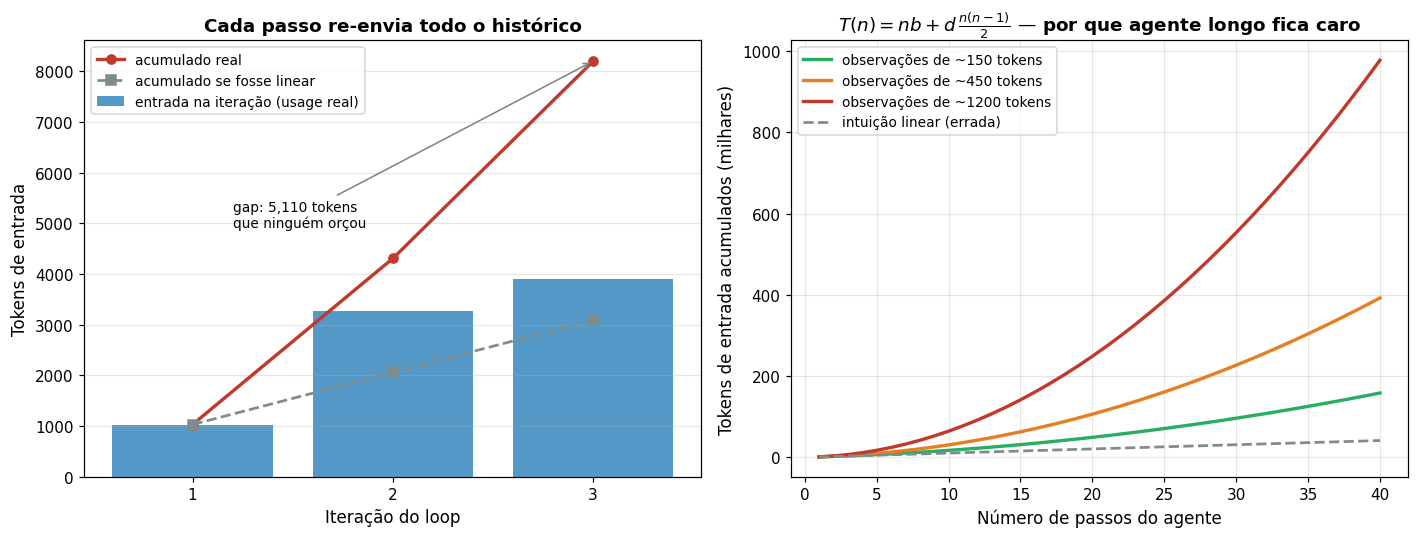

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

passos = np.arange(1, n_iter + 1)
acumulado = np.cumsum(entradas)
reta = b_med * passos

ax1.bar(passos, entradas, color="#2980b9", alpha=0.8, label="entrada na iteração (usage real)")
ax1.plot(passos, acumulado, "o-", color="#c0392b", linewidth=2.2, label="acumulado real")
ax1.plot(passos, reta, "s--", color="#7f8c8d", linewidth=1.8, label="acumulado se fosse linear")
ax1.set_xlabel("Iteração do loop", fontsize=11)
ax1.set_ylabel("Tokens de entrada", fontsize=11)
ax1.set_title("Cada passo re-envia todo o histórico", fontsize=12, fontweight="bold")
ax1.set_xticks(passos); ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3, axis="y")
ax1.annotate(f"gap: {acumulado[-1] - reta[-1]:,.0f} tokens\nque ninguém orçou",
             xy=(passos[-1], acumulado[-1]), xytext=(passos[0] + 0.2, acumulado[-1] * 0.60),
             fontsize=9, arrowprops=dict(arrowstyle="->", color="gray"))

n = np.arange(1, 41)
for d, cor in [(150, "#27ae60"), (450, "#e67e22"), (1200, "#c0392b")]:
    ax2.plot(n, custo_teorico(n, b_med, d) / 1000, linewidth=2.2, color=cor,
             label=f"observações de ~{d} tokens")
ax2.plot(n, (b_med * n) / 1000, "--", color="#7f8c8d", linewidth=1.8, label="intuição linear (errada)")
ax2.set_xlabel("Número de passos do agente", fontsize=11)
ax2.set_ylabel("Tokens de entrada acumulados (milhares)", fontsize=11)
ax2.set_title(r"$T(n) = nb + d\,\frac{n(n-1)}{2}$ — por que agente longo fica caro",
              fontsize=12, fontweight="bold")
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 9. As três defesas

Mesmo loop, mesma tarefa, mesma resposta. Só a conta muda.

1. **Teto de orçamento** — corta antes de a conta fugir.
2. **Compaction** — observações antigas viram resumo; é o que reduz o `d`.
3. **Prompt caching** — o prefixo (system + schemas) é estável entre iterações.

> Sobre o item 3: a política e o desconto de caching mudam com frequência. Confirme a vigente
> antes de prometer número para alguém — e repare que o campo `cache_read_input_tokens` é o
> que prova se o cache pegou de verdade.

In [ ]:
resposta_c, trace_c = rodar_agente(TAREFA, janela_compaction=2, verboso=False)

total_sem = float(np.sum([p["input_tokens"] for p in trace]))
total_com = float(np.sum([p["input_tokens"] for p in trace_c]))

print(f"Sem defesa:              {total_sem:>9,.0f} tokens de entrada   ({n_iter} iterações)")
print(f"Com compaction (j=2):    {total_com:>9,.0f} tokens de entrada   ({len(trace_c)} iterações)")
if total_com < total_sem:
    print(f"--> {1 - total_com/total_sem:.0%} a menos")
else:
    print("--> nesta execução não economizou: com poucos passos, o resumo não compensa.")

print("\n" + textwrap.fill(resposta_c, 78))
print("\nATENÇÃO: esses números são DESTA execução, com ESTA base. Não são benchmark.")
print("O que você leva daqui é o método de medir — o número do seu cliente sai do usage dele.")

Sem defesa:                  8,273 tokens de entrada   (3 iterações)
Com compaction (j=2):        8,223 tokens de entrada   (3 iterações)
--> 1% a menos

O crescimento nominal de 2023 para 2024 foi de 8,76%, ou R$ 51.667 por mês.
Mas essa comparação não é confiável como está, porque as notas explicativas
apontam dois fatores que inflam o número.  **Números brutos** - Consolidado
2023: R$ 7.080.000 - Consolidado 2024: R$ 7.700.000 - Variação: R$ 620.000 por
ano, ou cerca de R$ 51.667 por mês, equivalente a 8,76%.  **Por que a
comparação é enganosa**  1. **Aquisição da Vetor Nordeste (2023).** A unidade
Nordeste foi consolidada apenas a partir de 1º de abril de 2023. Ou seja, o
exercício de 2023 traz nove meses dessa unidade, e o de 2024 traz doze. As
notas dizem expressamente que a unidade Nordeste não é comparável a exercícios
anteriores sem ajuste pro forma. Parte do crescimento vem, portanto, de três
meses a mais de uma unidade incorporada, e não de crescimento orgânico. O
ajuste pro

## Para levar

- Rode de novo trocando `MODELO` por um modelo maior e compare **passos** e **tokens**, não só a
  resposta. Modelo melhor costuma resolver em menos passos — e às vezes sai mais barato.
- Troque a pergunta por uma que force mais consultas às notas (ex.: "compare 2019 com 2025 e
  liste todos os eventos que quebram a comparabilidade"). Veja o `d` subir e o gráfico mudar
  de forma.
- Pegue o `b` e o `d` do **seu** pipeline e jogue em `custo_teorico`. Se o seu agente dá mais
  de 10 passos, é melhor levar o susto agora do que na fatura.

**Próxima live:** por que juntar vários agentes quase sempre piora o resultado — e as três
situações em que não piora.